In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")

x_train = train.iloc[:, 1:].values / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (27455, 784)
Testing data: (27455, 784)


In [3]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(26, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 26)             │         1,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,426 (431.35 KB)

 Trainable params: 110,426 (431.35 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [5]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3117 - loss: 2.3450 - val_accuracy: 0.4901 - val_loss: 1.6840
Epoch 2/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5718 - loss: 1.3978 - val_accuracy: 0.6307 - val_loss: 1.1680
Epoch 3/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6760 - loss: 1.0479 - val_accuracy: 0.7075 - val_loss: 0.9153
Epoch 4/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7451 - loss: 0.8290 - val_accuracy: 0.7731 - val_loss: 0.7230
Epoch 5/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8065 - loss: 0.6475 - val_accuracy: 0.7724 - val_loss: 0.6774
Epoch 6/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8414 - loss: 0.5293 - val_accuracy: 0.8394 - val_loss: 0.5182
Epoch 7/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8729 - loss: 0.4299 - val_accuracy: 0.8419 - val_loss: 0.4492
Epoch 8/11
344/344 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8963 - loss: 0.3520 - val_accuracy: 0.

In [6]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

858/858 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step - accuracy: 0.9729 - loss: 0.1351
Test Loss: 0.13505196571350098
Test Accuracy: 0.9729011058807373


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


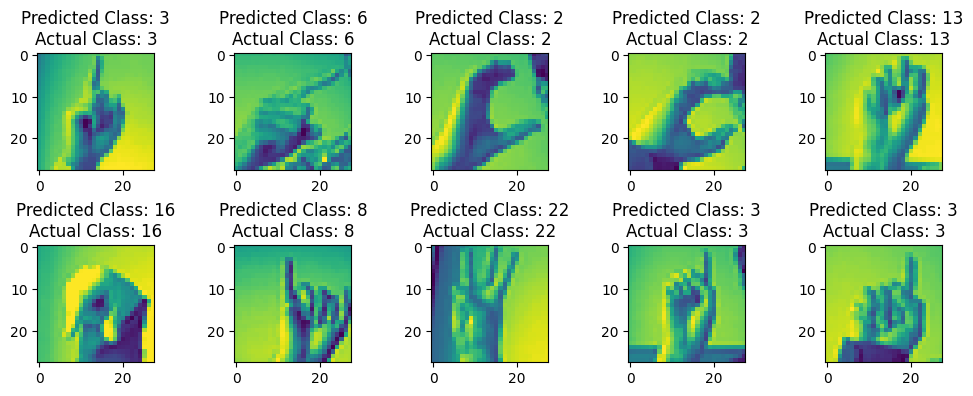

In [15]:
prediction = model.predict(x_test[:10])
predicted = prediction.argmax(axis = 1)

plt.figure(figsize=(10 , 4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i].reshape(28 , 28))
    plt.title(f"Predicted Class: {predicted[i]}\nActual Class: {y_test[i]}")

plt.tight_layout()
plt.show()

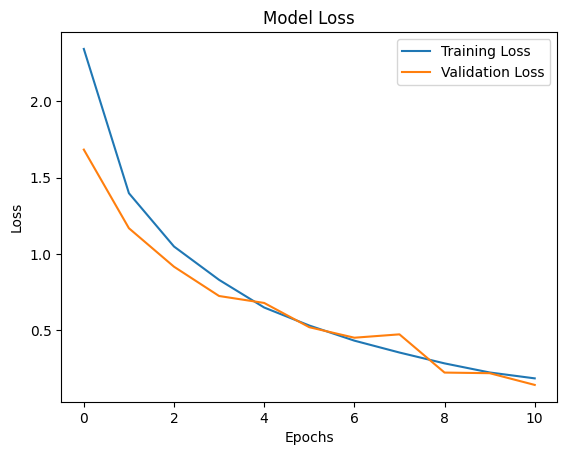

In [16]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

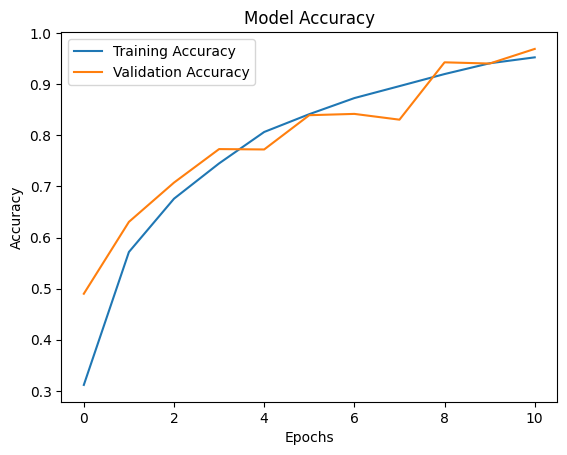

In [17]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [18]:
prediction = model.predict(x_test[:1])

print("Predicted Label:", np.argmax(prediction[0]))
print("Actual Label:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Predicted Label: 3
Actual Label: 3
